# 01 — Exploration et diagnostic des données
Rapport complet : `reports/01_data_quality_report.md`. Les chiffres viennent de `python main.py --stage diagnose`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import load_config
cfg = load_config()
R = ROOT / "reports"; FIG = R / "figures"
def load(name): return json.loads((R / name).read_text())
def fig(name): display(Image(filename=str(FIG / name)))

## Le fichier brut (chargé par `src.data.loader`)

In [2]:
from src.data.loader import load_raw
raw = load_raw(Path(cfg['data']['raw_dir']) / cfg['data']['raw_file'])
print(raw.shape); display(raw.head()); display(raw.dtypes.to_frame('dtype'))

(2075259, 8)


,timestamp,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


,dtype
timestamp,datetime64[us]
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


## Horodatage et valeurs manquantes

In [3]:
d = load('01_diagnosis_results.json')
display(pd.Series(d['timestamps']).to_frame('valeur'))
display(pd.Series(d['missing_pattern']).drop('nan_per_column').to_frame('valeur'))
display(pd.DataFrame(d['missing_runs']['by_length']).T)

,valeur
n_rows,2075259
start,2006-12-16 17:24:00
end,2010-11-26 21:02:00
span_days,1441.15
expected_minutes,2075259
absent_timestamps,0
is_monotonic_increasing,True
duplicate_timestamps,0
step_counts,{'0 days 00:01:00': 2075258}
seconds_not_zero,0


,valeur
rows_with_any_nan,25979
rows_with_all_nan,25979
rows_partially_nan,0
pct_rows_missing,1.252


,runs,minutes
1 min,38,38
2-10 min,18,44
11-60 min,6,206
1 h - 1 day,3,1044
> 1 day,6,24647


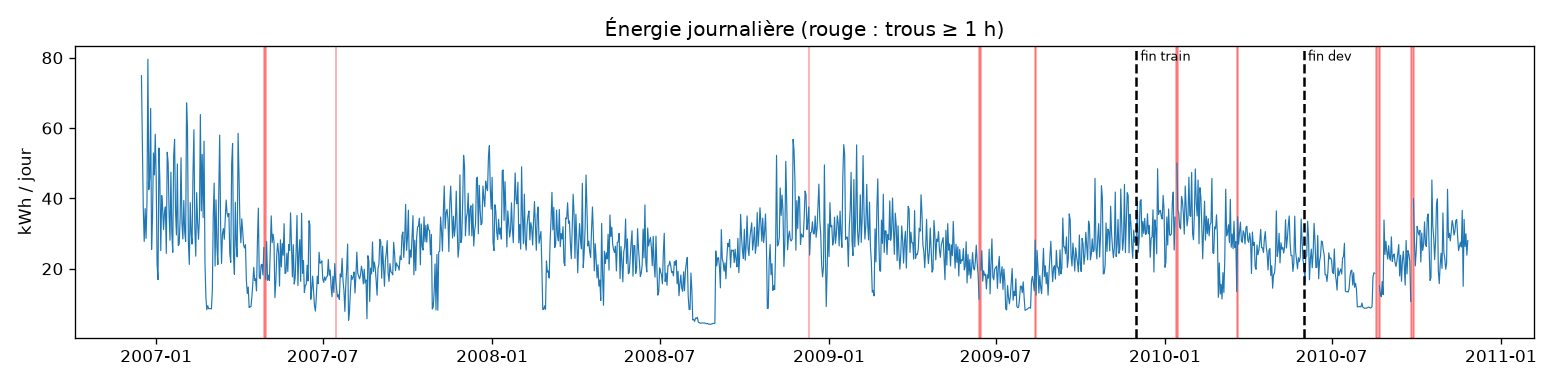

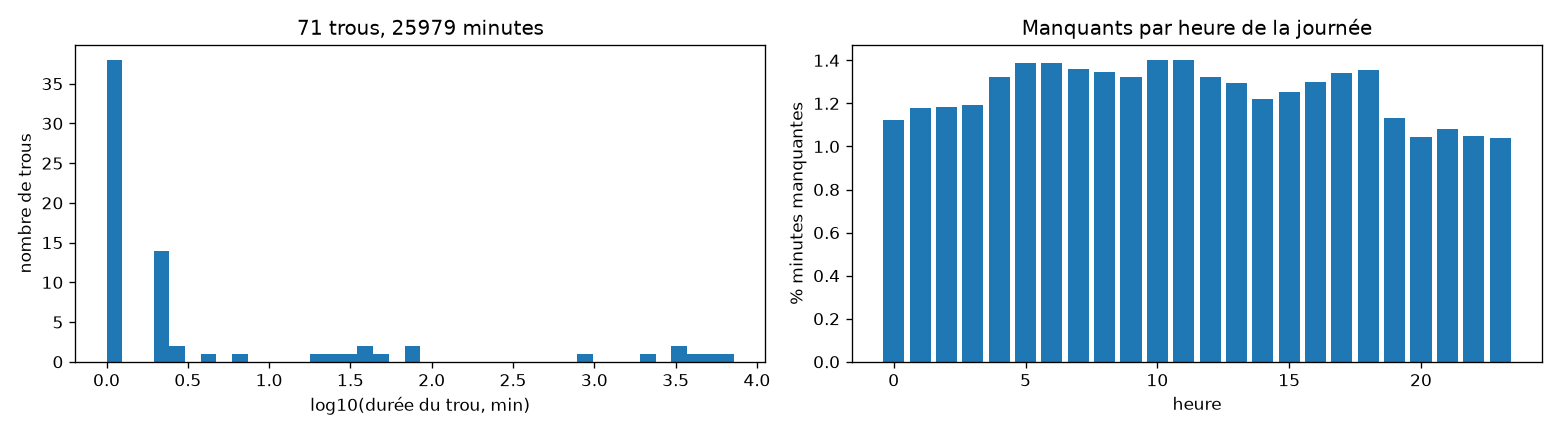

In [4]:
fig('01_daily_energy_gaps.png'); fig('01_missing_runs.png')

## Distributions et cohérence physique

,mean,min,q0.1%,q1%,q25%,median,q75%,q99%,q99.9%,max,zeros_pct
Global_active_power,1.092,0.076,0.08,0.11,0.308,0.602,1.528,4.850,6.790,11.122,0.000
Global_reactive_power,0.124,0.000,0.00,0.00,0.048,0.100,0.194,0.478,0.698,1.390,23.205
Voltage,240.840,223.200,228.55,232.14,238.990,241.010,242.890,248.270,250.630,254.150,0.000
Global_intensity,4.628,0.200,0.20,0.60,1.400,2.600,6.400,20.600,29.000,48.400,0.000
Sub_metering_1,1.122,0.000,0.00,0.00,0.000,0.000,0.000,38.000,44.000,88.000,90.600
Sub_metering_2,1.298,0.000,0.00,0.00,0.000,0.000,1.000,36.000,71.000,80.000,69.236
Sub_metering_3,6.458,0.000,0.00,0.00,0.000,1.000,17.000,20.000,30.000,31.000,41.060


,valeur
intensity_vs_estimate_corr,0.99937
intensity_median_rel_err_pct,2.00000
intensity_rel_err_gt_10pct_rows,185169.00000
submeter_share_of_energy_pct,48.80000
other_energy_negative_rows,33.00000
other_energy_negative_pct,0.00160
voltage_outside_207_253V_pct,0.00280
power_factor_median,0.99300


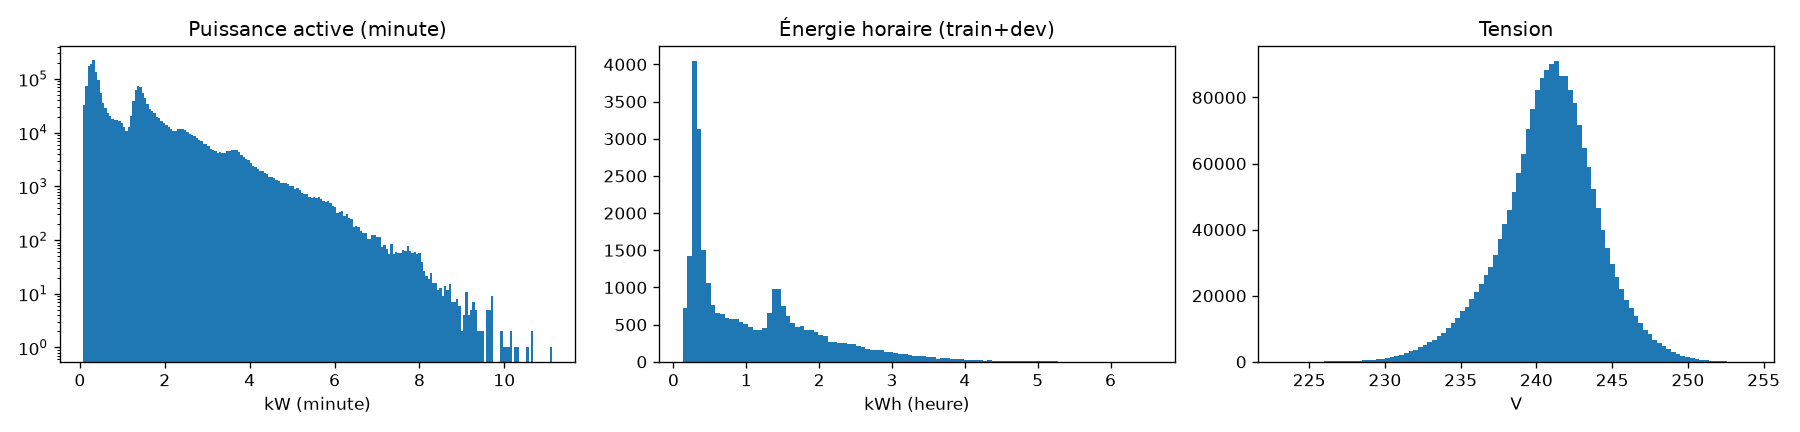

In [5]:
display(pd.DataFrame(d['describe']).T.round(3)); display(pd.Series(d['physics']).to_frame('valeur'))
fig('01_distributions.png')

## Saisonnalités, ACF/PACF, stationnarité (train + dev seulement)

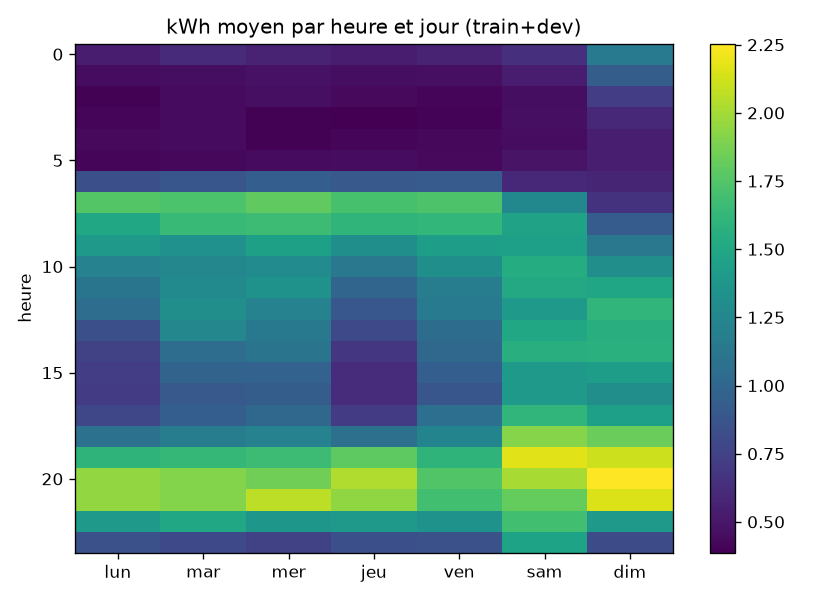

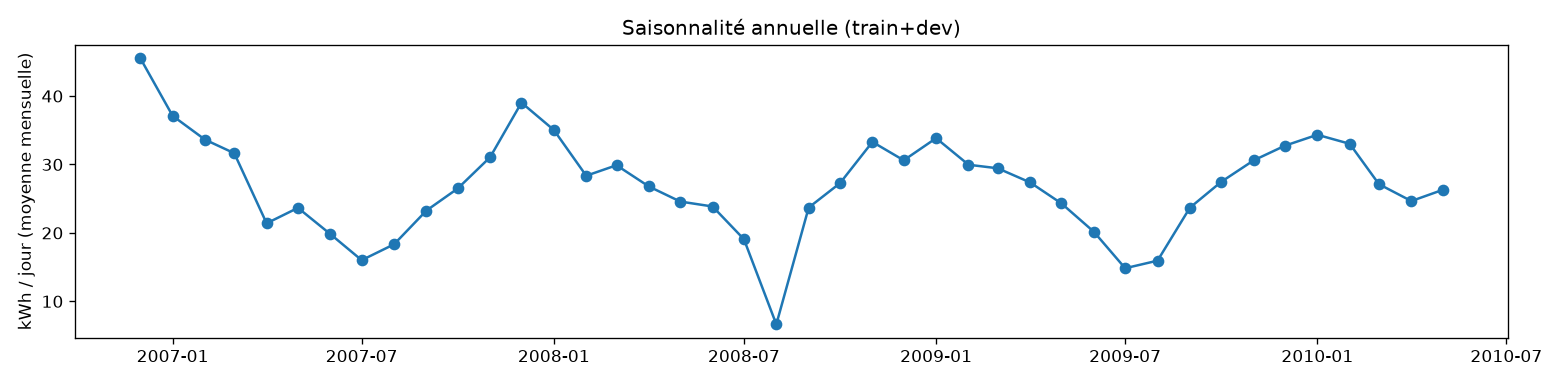

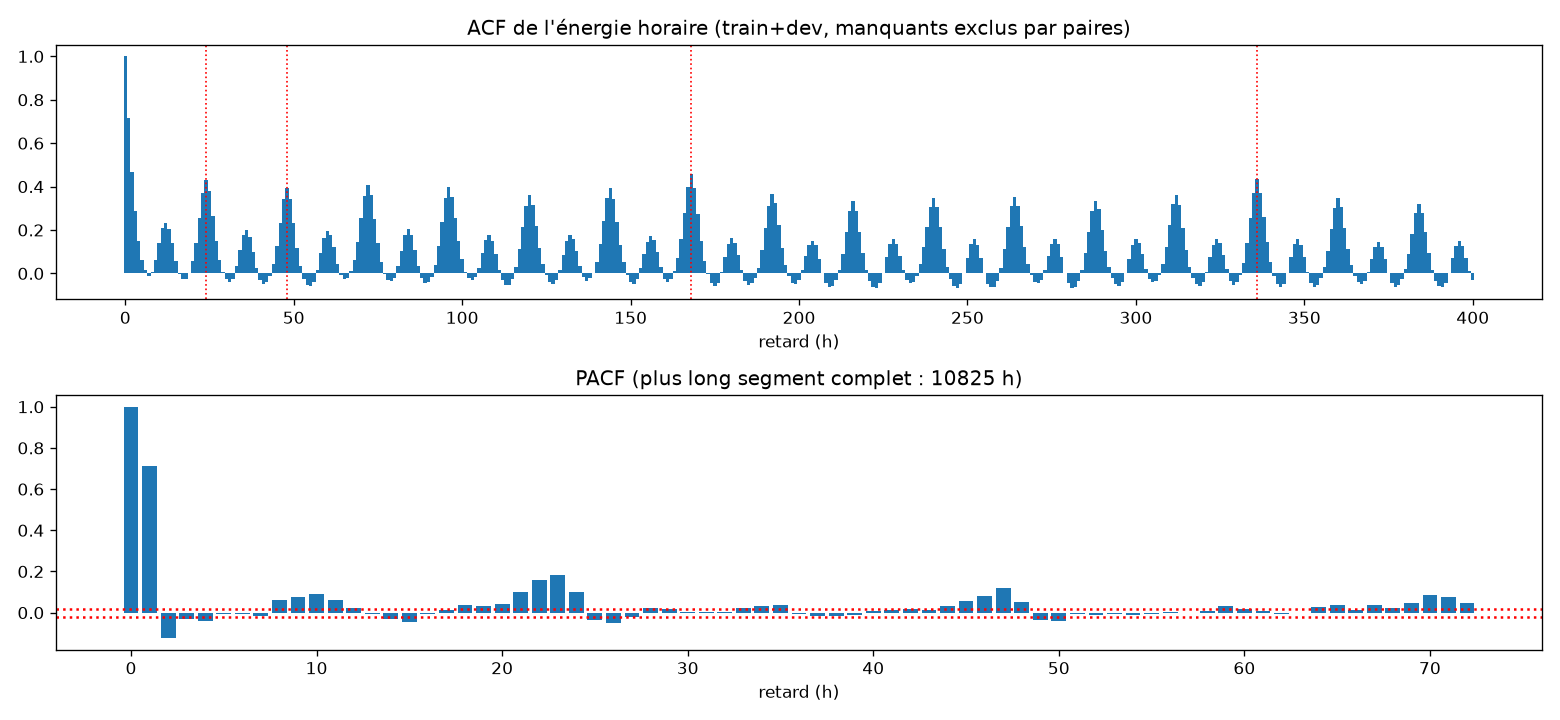

,1,2,3,6,12,23,24,25,48,144,168,336
ACF,0.716,0.467,0.287,0.014,0.233,0.37,0.43,0.381,0.396,0.392,0.458,0.434


,valeur
n_days,1250.0000
adf_stat,-3.2420
adf_pvalue,0.0177
kpss_stat,0.1680
kpss_pvalue,0.1000


In [6]:
fig('01_profile_hour_weekday.png'); fig('01_monthly.png'); fig('01_acf_pacf.png')
display(pd.Series(d['acf']).to_frame('ACF').T); display(pd.Series(d['stationarity_daily']).to_frame('valeur'))